<a href="https://colab.research.google.com/github/tatendagonzo/zimbabwe-used-vehicle-market-analysis/blob/main/notebooks/vehicle_market_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Zimbabwe Used Vehicle Market Analysis
**Author:** Tatenda Alistair Gonzo  
**Snapshot date:** 5 November 2026  
**Tools:** Python, Pandas, NumPy and Matplotlib

This notebook explores 21 publicly advertised vehicle listing observations. It demonstrates data inspection, cleaning checks, descriptive statistics and visualisation. The sample is small, non-random and heavily weighted toward Toyota Axio listings; it is not representative of Zimbabwe's full vehicle market.

## 1. Load libraries and data
Run from the repository root in Jupyter. In Google Colab, upload the CSV when prompted.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path('data/used_vehicles.csv')
RAW_CSV_URL = 'https://raw.githubusercontent.com/tatendagonzo/zimbabwe-used-vehicle-market-analysis/main/data/used_vehicles.csv'

if DATA_PATH.exists():
    vehicles = pd.read_csv(DATA_PATH)
else:
    try:
        # In Google Colab, load the public CSV directly from this GitHub repository.
        vehicles = pd.read_csv(RAW_CSV_URL)
    except Exception:
        # Fallback for environments where the GitHub raw file cannot be reached.
        try:
            from google.colab import files
            uploaded = files.upload()
            csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
            if not csv_files:
                raise FileNotFoundError('Please upload used_vehicles.csv')
            vehicles = pd.read_csv(csv_files[0])
        except ImportError as exc:
            raise FileNotFoundError('Run from the repository root or make the CSV available at data/used_vehicles.csv.') from exc

print(f'Loaded {len(vehicles)} observations and {len(vehicles.columns)} columns.')
display(vehicles.head())

Loaded 21 observations and 15 columns.


,listing_id,make,model,year,price,currency,mileage_km,transmission,fuel_type,body_type,location,date_collected,source_name,listing_url,notes
0,ZWV001,Toyota,Axio,2017,12000,USD,56000,Automatic,Petrol,Sedan,Harare,2026-11-05,AutoTrader Zimbabwe,https://www.autotrader.co.zw/cars/for-sale/har...,Search-results listing; recent import
1,ZWV002,Toyota,Axio,2016,13800,USD,67000,Automatic,Petrol,Sedan,Harare,2026-11-05,AutoTrader Zimbabwe,https://www.autotrader.co.zw/cars/for-sale/har...,Search-results listing; recent import
2,ZWV003,Toyota,Axio,2014,9500,USD,105000,Automatic,Petrol,Sedan,Harare,2026-11-05,AutoTrader Zimbabwe,https://www.autotrader.co.zw/cars/for-sale/har...,Search-results listing; used
3,ZWV004,Toyota,Axio,2014,10800,USD,81000,Automatic,Petrol,Sedan,Harare,2026-11-05,AutoTrader Zimbabwe,https://www.autotrader.co.zw/cars/for-sale/har...,Advertised as before duty
4,ZWV005,Toyota,Axio,2012,9500,USD,128000,Automatic,Petrol,Sedan,Harare,2026-11-05,AutoTrader Zimbabwe,https://www.autotrader.co.zw/cars/for-sale/har...,Search-results listing; used


## 2. Inspect structure and data types

In [2]:
print('Dataset shape:', vehicles.shape)
display(vehicles.dtypes.to_frame('data_type'))
display(vehicles.isna().sum().to_frame('missing_values'))

Dataset shape: (21, 15)


,data_type
listing_id,object
make,object
model,object
year,int64
price,int64
currency,object
mileage_km,int64
transmission,object
fuel_type,object
body_type,object


,missing_values
listing_id,0
make,0
model,0
year,0
price,0
currency,0
mileage_km,0
transmission,3
fuel_type,3
body_type,0


## 3. Prepare analysis fields
Original columns are retained. Missing values are not filled with invented values.

In [3]:
for column in ['year', 'price', 'mileage_km']:
    vehicles[column] = pd.to_numeric(vehicles[column], errors='coerce')
vehicles['date_collected'] = pd.to_datetime(vehicles['date_collected'], errors='coerce')
vehicles['currency'] = vehicles['currency'].astype('string').str.upper()
usd_vehicles = vehicles.loc[vehicles['currency'].eq('USD')].copy()
print('USD observations:', len(usd_vehicles))
print('Duplicate project IDs:', vehicles['listing_id'].duplicated().sum())
display(usd_vehicles[['listing_id', 'make', 'model', 'year', 'price', 'mileage_km']].head())

USD observations: 21
Duplicate project IDs: 0


,listing_id,make,model,year,price,mileage_km
0,ZWV001,Toyota,Axio,2017,12000,56000
1,ZWV002,Toyota,Axio,2016,13800,67000
2,ZWV003,Toyota,Axio,2014,9500,105000
3,ZWV004,Toyota,Axio,2014,10800,81000
4,ZWV005,Toyota,Axio,2012,9500,128000


## 4. Descriptive statistics
These are sample-level summaries, not estimates for the whole Zimbabwe market.

In [4]:
display(usd_vehicles[['price', 'year', 'mileage_km']].describe().round(2))
print('Median asking price (USD):', usd_vehicles['price'].median())
print('Median mileage (km):', usd_vehicles['mileage_km'].median())
print('\nCounts by make:')
display(vehicles['make'].value_counts(dropna=False))
print('\nCounts by model:')
display(vehicles['model'].value_counts(dropna=False))

,price,year,mileage_km
count,21.00,21.00,21.00
mean,13923.81,2015.95,72602.90
std,8583.99,2.62,31562.89
min,7800.00,2009.00,12500.00
25%,10500.00,2014.00,62000.00
50%,12500.00,2016.00,71000.00
75%,13800.00,2017.00,89564.00
max,50000.00,2021.00,128000.00


Median asking price (USD): 12500.0
Median mileage (km): 71000.0

Counts by make:


,count
make,
Toyota,19
Honda,1
Nissan,1



Counts by model:


,count
model,
Axio,18
Fit,1
X-Trail,1
Fortuner,1


## 5. Visualise asking-price distribution

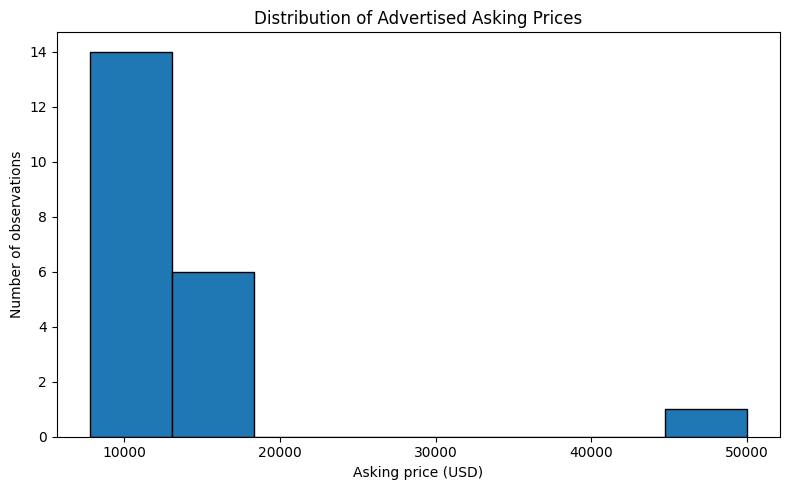

In [5]:
VISUALS_DIR = Path('visuals')
VISUALS_DIR.mkdir(exist_ok=True)
plt.figure(figsize=(8, 5))
plt.hist(usd_vehicles['price'].dropna(), bins=8, edgecolor='black')
plt.title('Distribution of Advertised Asking Prices')
plt.xlabel('Asking price (USD)')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.savefig(VISUALS_DIR / 'price_distribution.png', dpi=160)
plt.savefig(VISUALS_DIR / 'price_distribution.svg')
plt.show()

## 6. Compare median asking price by model year
Small groups should be interpreted cautiously.

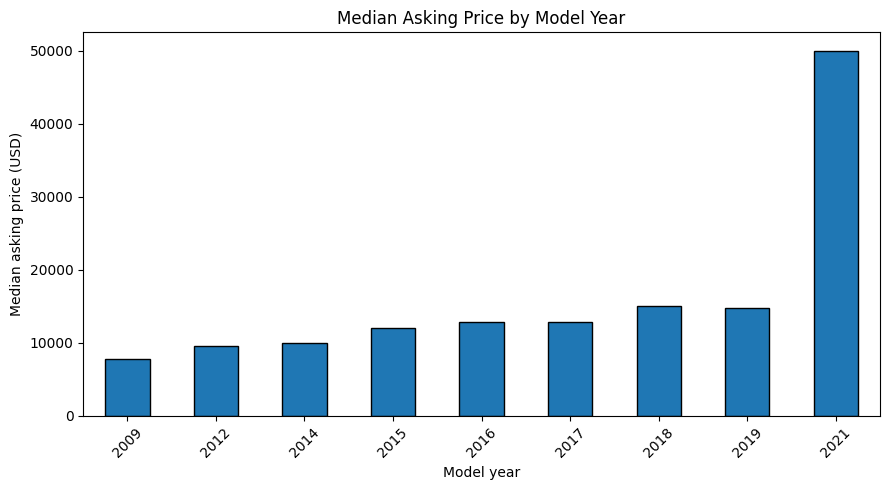

In [6]:
price_by_year = usd_vehicles.groupby('year')['price'].median().sort_index()
plt.figure(figsize=(9, 5))
price_by_year.plot(kind='bar', edgecolor='black')
plt.title('Median Asking Price by Model Year')
plt.xlabel('Model year')
plt.ylabel('Median asking price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(VISUALS_DIR / 'median_price_by_year.png', dpi=160)
plt.savefig(VISUALS_DIR / 'median_price_by_year.svg')
plt.show()

## 7. Explore mileage and asking price
A correlation is descriptive only and does not establish causation.

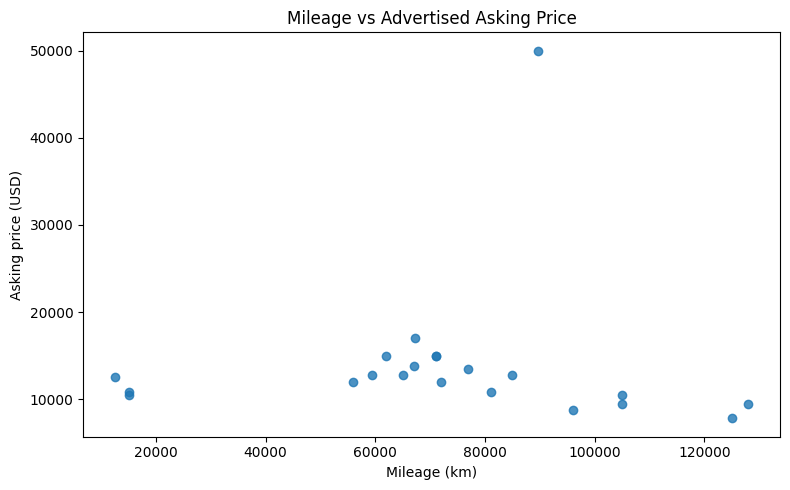

Sample Pearson correlation: 0.022


In [7]:
mileage_price = usd_vehicles.dropna(subset=['mileage_km', 'price'])
plt.figure(figsize=(8, 5))
plt.scatter(mileage_price['mileage_km'], mileage_price['price'], alpha=0.8)
plt.title('Mileage vs Advertised Asking Price')
plt.xlabel('Mileage (km)')
plt.ylabel('Asking price (USD)')
plt.tight_layout()
plt.savefig(VISUALS_DIR / 'mileage_vs_price.png', dpi=160)
plt.savefig(VISUALS_DIR / 'mileage_vs_price.svg')
plt.show()
if len(mileage_price) >= 3:
    print('Sample Pearson correlation:', round(mileage_price['mileage_km'].corr(mileage_price['price']), 3))

## 8. Review missing values and possible duplicates
Potential duplicates are flagged for human review. Matching attributes do not prove two result cards refer to the same advert.

,missing_count,missing_percent
transmission,3,14.3
fuel_type,3,14.3
listing_id,0,0.0
year,0,0.0
price,0,0.0
make,0,0.0
model,0,0.0
mileage_km,0,0.0
currency,0,0.0
body_type,0,0.0


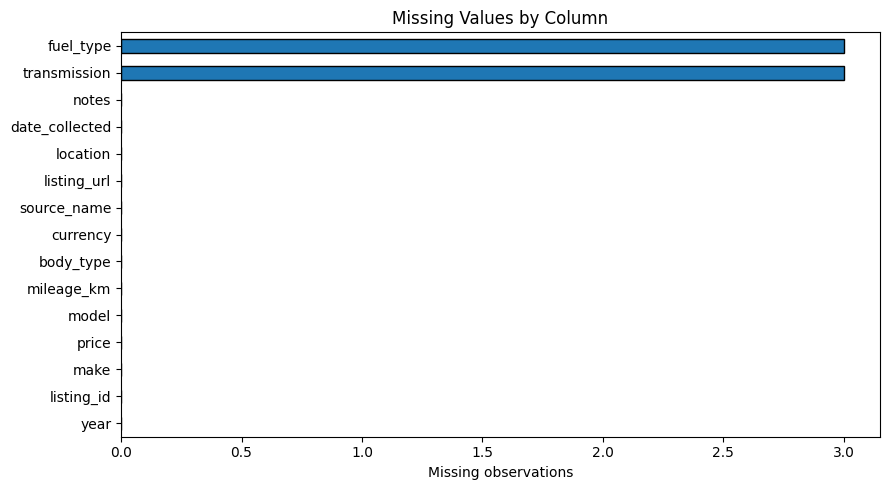

,listing_id,make,model,year,price,mileage_km,source_name
5,ZWV006,Toyota,Axio,2018,15000,71000,AutoTrader Zimbabwe
15,ZWV016,Toyota,Axio,2018,15000,71000,Classifieds.co.zw


In [8]:
quality = pd.DataFrame({'missing_count': vehicles.isna().sum(), 'missing_percent': (vehicles.isna().mean() * 100).round(1)}).sort_values('missing_percent', ascending=False)
display(quality)
plt.figure(figsize=(9, 5))
quality['missing_count'].sort_values().plot(kind='barh', edgecolor='black')
plt.title('Missing Values by Column')
plt.xlabel('Missing observations')
plt.tight_layout()
plt.savefig(VISUALS_DIR / 'missing_values.png', dpi=160)
plt.savefig(VISUALS_DIR / 'missing_values.svg')
plt.show()
duplicate_fields = ['make', 'model', 'year', 'price', 'mileage_km']
possible_duplicate_mask = vehicles.duplicated(subset=duplicate_fields, keep=False)
possible_duplicates = vehicles.loc[possible_duplicate_mask, ['listing_id', *duplicate_fields, 'source_name']].sort_values(duplicate_fields)
display(possible_duplicates)

## 9. Summary and limitations
The dataset is a small convenience sample dominated by Toyota Axio listings. Asking prices are not confirmed sale prices. Source URLs point to results/category pages, not individual adverts. Rerun the analysis after source-level verification and dataset expansion before drawing stronger conclusions.

In [9]:
print(f'Observations analysed: {len(vehicles)}')
print(f'Median asking price: US${usd_vehicles["price"].median():,.0f}')
print(f'Median advertised mileage: {usd_vehicles["mileage_km"].median():,.0f} km')
print('Most common make:', vehicles['make'].mode().iat[0] if not vehicles['make'].mode().empty else 'N/A')
print('Potential duplicate rows flagged:', int(possible_duplicate_mask.sum()))
print('Charts saved to:', VISUALS_DIR.resolve())

Observations analysed: 21
Median asking price: US$12,500
Median advertised mileage: 71,000 km
Most common make: Toyota
Potential duplicate rows flagged: 2
Charts saved to: /content/visuals
